# 01 — Problem Framing and Dataset Preparation
**Intelligent Retail Decision Assistant — Phase 1**

Goal: define the retail use case, load and inspect the base dataset, document original vs engineered columns, and produce a clean data dictionary that later phases reuse.

## Task 1.1 — Business use case and questions
A mid-sized Indian online retailer (Shoes, Apparel, Accessories) wants one assistant serving **business users** and **customers**.

| # | Business question | Phase / method |
|---|---|---|
| Q1 | Which interactions convert into a purchase, and what drives conversion? | Phase 2 — supervised (`purchase_flag`) |
| Q2 | What customer segments exist, and which is most price-sensitive? | Phase 2 — clustering |
| Q3 | Which products fit a shopper's need, budget and occasion? | Phase 3–4 — RAG over product text |
| Q4 | What do return / refund / exchange / shipping / warranty policies say? | Phase 4 — grounded policy QA with citations |
| Q5 | How do we route a free-text request to the right tool? | Phase 5 — agent / controller |

## Task 1.2 — Setup and load the dataset

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")

# Project root = parent of notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "retail_interactions.csv"
POLICIES = ROOT / "data" / "policies" / "retail_policies.json"
PROCESSED = ROOT / "data" / "processed"
OUTPUTS = ROOT / "outputs"
PROCESSED.mkdir(parents=True, exist_ok=True); OUTPUTS.mkdir(exist_ok=True)

# keep_default_na=False: the literal string "NA" in `size` must not silently vanish;
# we treat it explicitly below.
df_raw = pd.read_csv(RAW, keep_default_na=False, na_values=[""])
print("Shape:", df_raw.shape)
df_raw.head(3)

Shape: (1500, 46)


,customer_id,age,gender,city_tier,state,income_band,occupation,membership_level,days_since_last_purchase,avg_order_value,total_orders,preferred_channel,product_id,category,sub_category,brand,base_price,discount_percent,final_price,avg_product_rating,stock_level,color,size,material,season,is_returnable,purchase_flag,quantity,payment_mode,delivery_type,time_on_page,added_to_cart,wishlist_flag,returned_flag,rating_given,review_sentiment_label,product_title,product_description,customer_review_text,customer_query,policy_doc_id,policy_text_snippet,image_path,recommended_use_case,style_tags,occasion_tags
0,C100,26,Male,Tier-3,Tamil Nadu,Low,Self-Employed,Platinum,42,3334.08,3,App,P1000,Accessories,Backpack,Fastrack,3478.35,0,3478.35,4.2,28,Blue,XL,Leather,Winter,1,0,1,Wallet,Standard,250.7,1,0,0,4,positive,Fastrack Blue Backpack Leather Accessorie,A blue backpack from Fastrack made with leathe...,Loved the blue accessories product. Good quali...,Need a blue backpack for travel under Rs. 4478,POL_WARRANTY,Watches and selected accessories carry a 6-mon...,images/P1000.jpg,Travel,"Blue, Leather, Travel",Travel
1,C101,45,Female,Tier-2,Maharashtra,Low,Teacher,Bronze,23,4151.07,5,App,P1001,Shoes,Sneakers,Bata,1613.88,30,1129.72,2.8,29,Blue,NA,Mesh,All-Season,1,1,1,Wallet,Express,246.5,1,0,0,5,positive,Bata Blue Sneakers Mesh Shoes,A blue sneakers from Bata made with mesh. Desi...,Loved the blue shoes product. Good quality and...,Need a blue sneakers for daily wear under Rs. ...,POL_REFUND,Refunds are processed after the returned item ...,images/P1001.jpg,Daily Wear,"Blue, Mesh, Daily Wear",Daily Wear
2,C102,54,Male,Tier-3,Delhi,Low,Engineer,Gold,24,2609.11,13,App,P1002,Shoes,Sneakers,Nike,2661.34,15,2262.14,4.1,30,Grey,L,Leather,Monsoon,1,1,1,COD,Express,80.3,1,0,1,3,neutral,Nike Grey Sneakers Leather Shoes,A grey sneakers from Nike made with leather. D...,The product was average. The grey look was fin...,Need a grey sneakers for office under Rs. 3262,POL_EXCHANGE,Size exchanges are allowed within 10 days of d...,images/P1002.jpg,Office,"Grey, Leather, Office",Office


## Task 1.3 — Inspect schema

In [2]:
schema = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "n_unique": df_raw.nunique(),
    "example": df_raw.iloc[0],
})
print(f"Rows: {len(df_raw)} | Customers: {df_raw.customer_id.nunique()} | Products: {df_raw.product_id.nunique()}")
print("Duplicate rows:", df_raw.duplicated().sum())
schema

Rows: 1500 | Customers: 250 | Products: 300
Duplicate rows: 0


,dtype,n_unique,example
customer_id,str,250,C100
age,int64,43,26
gender,str,2,Male
city_tier,str,3,Tier-3
state,str,5,Tamil Nadu
income_band,str,3,Low
occupation,str,5,Self-Employed
membership_level,str,4,Platinum
days_since_last_purchase,int64,110,42
avg_order_value,float64,1491,3334.08


## Task 1.4 — Missingness and data-quality checks

In [3]:
# 1) True nulls
nulls = df_raw.isna().sum()
print("Columns with nulls:", nulls[nulls > 0].to_dict() or "none")

# 2) Placeholder values that mean 'missing'
print("size == 'NA':", (df_raw["size"] == "NA").sum(), "rows")
print(df_raw.groupby("category")["size"].apply(lambda s: (s == "NA").sum()))

# 3) Consistency: final_price = base_price * (1 - discount/100)
gap = (df_raw.final_price - df_raw.base_price * (1 - df_raw.discount_percent / 100)).abs().max()
print(f"Max price formula gap: {gap:.3f}  (rounding only)")

# 4) Logical rule: a return requires a purchase
print("\nPurchase vs Return:"); print(pd.crosstab(df_raw.purchase_flag, df_raw.returned_flag))

# 5) Leakage check: sentiment label is derived from rating
print("\nRating vs sentiment:"); print(pd.crosstab(df_raw.rating_given, df_raw.review_sentiment_label))

Columns with nulls: none
size == 'NA': 270 rows
category
Accessories    88
Apparel        90
Shoes          92
Name: size, dtype: int64
Max price formula gap: 0.005  (rounding only)

Purchase vs Return:
returned_flag    0    1
purchase_flag          
0              730    0
1              503  267

Rating vs sentiment:
review_sentiment_label  negative  neutral  positive
rating_given                                       
2                            328        0         0
3                              0      512         0
4                              0        0       485
5                              0        0       175


**Findings**
- No true nulls. `size` has **270 'NA' placeholders** spread across all categories → treated as missing and imputed as `"Unknown"` in the ML pipeline.
- `final_price` is consistent with `base_price` and `discount_percent`.
- `returned_flag = 1` only occurs when `purchase_flag = 1` → returns must be modelled on purchased rows only.
- `review_sentiment_label` is a deterministic mapping of `rating_given` (2→negative, 3→neutral, 4–5→positive) → never use one to predict the other (leakage).

## Task 1.5 — Candidate targets and class balance

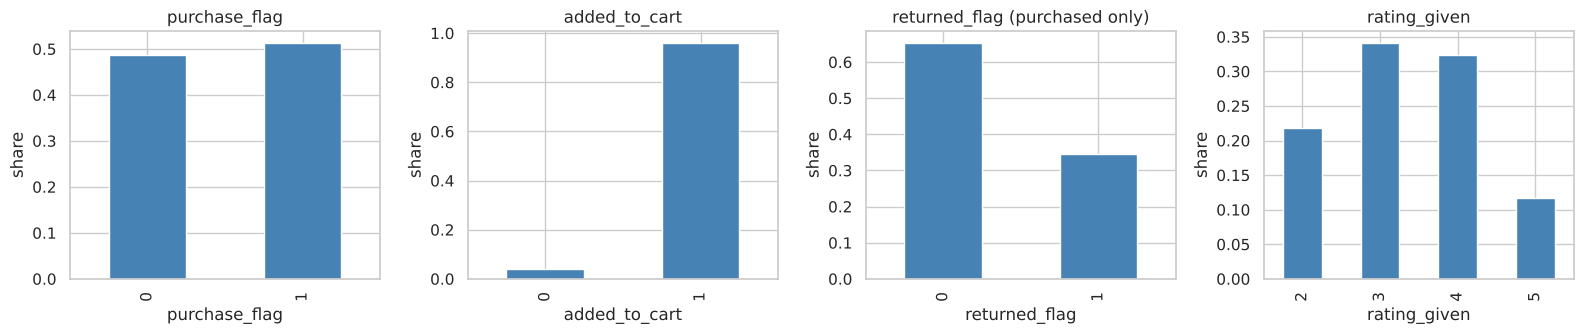

purchase_flag {0: 0.487, 1: 0.513}
added_to_cart {0: 0.039, 1: 0.961}
returned_flag {0: 0.653, 1: 0.347}
rating_given {2: 0.219, 3: 0.341, 4: 0.323, 5: 0.117}


In [4]:
targets = ["purchase_flag", "added_to_cart", "returned_flag", "rating_given"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, t in zip(axes, targets):
    sub = df_raw if t != "returned_flag" else df_raw[df_raw.purchase_flag == 1]
    sub[t].value_counts(normalize=True).sort_index().plot.bar(ax=ax, color="steelblue")
    ax.set_title(t + (" (purchased only)" if t == "returned_flag" else "")); ax.set_ylabel("share")
plt.tight_layout(); plt.savefig(OUTPUTS / "01_target_balance.png", dpi=120); plt.show()

for t in targets:
    sub = df_raw if t != "returned_flag" else df_raw[df_raw.purchase_flag == 1]
    print(t, sub[t].value_counts(normalize=True).round(3).sort_index().to_dict())

**Target decision (carried into Phase 2):** `purchase_flag` — balanced (~51/49), directly tied to revenue, and available for every row.
`added_to_cart` is 96% positive (too imbalanced to be useful); `returned_flag` (~35% of purchases) is a good secondary target.

## Task 1.6 — Original vs engineered columns

In [5]:
ORIGINAL = {
 "Customer profile":  ["customer_id","age","gender","city_tier","state","income_band","occupation","membership_level"],
 "Customer history":  ["days_since_last_purchase","avg_order_value","total_orders","preferred_channel"],
 "Product profile":   ["product_id","category","sub_category","brand","color","size","material","season","is_returnable"],
 "Commercial data":   ["base_price","discount_percent","final_price","avg_product_rating","stock_level"],
 "Interaction data":  ["purchase_flag","quantity","payment_mode","delivery_type","time_on_page","added_to_cart","wishlist_flag"],
 "Post-purchase":     ["returned_flag","rating_given"],
}
ENGINEERED = {
 "review_sentiment_label": "Derived from rating_given (2=negative, 3=neutral, 4-5=positive)",
 "product_title":          "Template: brand + color + sub_category + material + category",
 "product_description":    "Template sentence from color, sub_category, brand, material, use case, category",
 "customer_review_text":   "Synthetic review text chosen to match the sentiment label",
 "customer_query":         "Synthetic shopper query: color + sub_category + use case + budget (final_price + ~Rs.1000)",
 "policy_doc_id":          "Policy id from retail_policies.json linked to the row",
 "policy_text_snippet":    "Text of that policy (data/policies/retail_policies.json)",
 "image_path":             "Placeholder path images/<product_id>.jpg (optional multimodal)",
 "recommended_use_case":   "Synthetic intended use (Travel, Daily Wear, Office, ...)",
 "style_tags":             "Comma-joined color, material, use case",
 "occasion_tags":          "Same as recommended_use_case, for semantic search",
}
orig_cols = [c for g in ORIGINAL.values() for c in g]
assert set(orig_cols) | set(ENGINEERED) == set(df_raw.columns), "column list mismatch"
print(f"Original/base columns: {len(orig_cols)} | Engineered/enriched columns: {len(ENGINEERED)}")

Original/base columns: 35 | Engineered/enriched columns: 11


> **Assumption:** the course-provided CSV is treated as the base dataset. Its tabular columns are "original";
> the text-rich GenAI columns are synthetic/engineered from those tabular fields using the templates above, so they
> can be reproduced from the tabular columns alone. Policies are synthetic and stored separately in `data/policies/`.

## Task 1.7 — Data dictionary

In [6]:
DESCRIPTIONS = {
 "customer_id":"Customer identifier","age":"Customer age (years)","gender":"Customer gender",
 "city_tier":"City tier (Tier-1/2/3)","state":"Indian state","income_band":"Income band (Low/Medium/High)",
 "occupation":"Occupation","membership_level":"Loyalty tier (Bronze/Silver/Gold/Platinum)",
 "days_since_last_purchase":"Recency in days","avg_order_value":"Historic average order value (Rs.)",
 "total_orders":"Historic order count","preferred_channel":"App / Web / Store",
 "product_id":"Product identifier","category":"Shoes / Apparel / Accessories","sub_category":"Product sub-type",
 "brand":"Brand","base_price":"List price (Rs.)","discount_percent":"Discount (%)",
 "final_price":"Price after discount (Rs.)","avg_product_rating":"Average product rating (1-5)",
 "stock_level":"Units in stock","color":"Color","size":"Size (S/M/L/XL; 'NA' = missing)",
 "material":"Material","season":"Season","is_returnable":"1 if product is returnable",
 "purchase_flag":"1 if the interaction ended in purchase (TARGET)","quantity":"Units in interaction",
 "payment_mode":"Payment method","delivery_type":"Standard / Express","time_on_page":"Seconds on product page",
 "added_to_cart":"1 if added to cart","wishlist_flag":"1 if wishlisted","returned_flag":"1 if returned",
 "rating_given":"Rating given by customer (2-5)",
}
DESCRIPTIONS.update(ENGINEERED)
group_of = {c: g for g, cols in ORIGINAL.items() for c in cols}
dd = pd.DataFrame({
    "column": df_raw.columns,
    "dtype": df_raw.dtypes.astype(str).values,
    "feature_group": [group_of.get(c, "GenAI enrichment") for c in df_raw.columns],
    "source": ["original" if c in group_of else "engineered" for c in df_raw.columns],
    "n_unique": df_raw.nunique().values,
    "description": [DESCRIPTIONS[c] for c in df_raw.columns],
})
dd.to_csv(OUTPUTS / "data_dictionary.csv", index=False)
dd

,column,dtype,feature_group,source,n_unique,description
0,customer_id,str,Customer profile,original,250,Customer identifier
1,age,int64,Customer profile,original,43,Customer age (years)
2,gender,str,Customer profile,original,2,Customer gender
3,city_tier,str,Customer profile,original,3,City tier (Tier-1/2/3)
4,state,str,Customer profile,original,5,Indian state
5,income_band,str,Customer profile,original,3,Income band (Low/Medium/High)
6,occupation,str,Customer profile,original,5,Occupation
7,membership_level,str,Customer profile,original,4,Loyalty tier (Bronze/Silver/Gold/Platinum)
8,days_since_last_purchase,int64,Customer history,original,110,Recency in days
9,avg_order_value,float64,Customer history,original,1491,Historic average order value (Rs.)


## Task 1.8 — Clean and save the processed dataset

In [7]:
df = df_raw.copy()
df["size"] = df["size"].replace("NA", np.nan)          # explicit missing; imputed in Phase 2 pipeline
df["price_band"] = pd.cut(df.final_price, [0, 1500, 3000, 5000, np.inf],
                          labels=["<1.5k", "1.5k-3k", "3k-5k", "5k+"])   # engineered helper
df.to_csv(PROCESSED / "retail_clean.csv", index=False)

with open(POLICIES) as f:
    policies = json.load(f)
print("Saved:", PROCESSED / "retail_clean.csv", df.shape)
print("Policies:", list(policies))
print(df.price_band.value_counts().sort_index().to_dict())

Saved: /home/user/demo/capstone_project/data/processed/retail_clean.csv (1500, 47)
Policies: ['POL_RETURNS', 'POL_EXCHANGE', 'POL_SHIPPING', 'POL_REFUND', 'POL_WARRANTY']
{'<1.5k': 377, '1.5k-3k': 655, '3k-5k': 413, '5k+': 55}


## Phase 1 summary
- 1,500 interaction rows, 250 customers, 300 products, 46 columns (35 original, 11 engineered).
- Only data-quality issue: 270 `size='NA'` placeholders → set to missing.
- Primary supervised target: `purchase_flag` (balanced). Secondary: `returned_flag` on purchases.
- Leakage risks noted: `review_sentiment_label`↔`rating_given`; `returned_flag` only exists after purchase.
- Outputs: `data/processed/retail_clean.csv`, `outputs/data_dictionary.csv`, `outputs/01_target_balance.png`.